# WoE baseline — расширенные геологические признаки

**Версия:** обновлённый baseline на `features_table_geo.csv`.

Цель — получить интерпретируемое ранжирование ячеек 1×1 км по сумме одномерных WoE-вкладов. Здесь `is_deposit=0` означает **Unlabeled background**, а не подтверждённое отсутствие золота. WoE — логарифм частоты признака среди известных месторождений относительно фоновой территории; итоговый score не является вероятностью.

В этой версии:
- используются пять числовых признаков и категориальная литология;
- границы квантильных бинов и WoE-таблицы обучаются только на train fold;
- метрики учитывают ничьи на границе top-K;
- ранг известного месторождения считается среди всех ячеек тестового фолда;
- OOF scores разных фолдов не объединяются в один глобальный рейтинг.


## 1. Загрузка и проверка данных

In [1]:

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TARGET = "is_deposit"
FOLD = "fold_id"
TOP_FRACTIONS = (0.01, 0.05, 0.10)
ALPHA = 0.5

def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "processed").exists():
            return candidate
    # Common location when notebook is opened from backend/notebooks
    candidate = Path("../../")
    if (candidate / "data" / "processed").exists():
        return candidate.resolve()
    raise FileNotFoundError(
        "Не найдена папка data/processed. Запустите ноутбук из репозитория "
        "или проверьте расположение данных."
    )

ROOT = find_project_root()
DATA_PATH = ROOT / "data" / "processed" / "features_table_geo.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Не найден файл: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
NUMERIC_FEATURES = [
    c for c in ["elevation", "magnetic", "gravity",
                "dist_fault_km", "dist_contact_km"] if c in df.columns
]
CATEGORICAL_FEATURES = [
    c for c in ["lithology_group"] if c in df.columns
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

required = set(FEATURES + [TARGET, FOLD, "x", "y"])
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError(f"В таблице отсутствуют обязательные колонки: {missing}")
if not set(df[TARGET].dropna().unique()).issubset({0, 1}):
    raise ValueError("is_deposit должен содержать только 0/1.")
if df[[TARGET, FOLD, "x", "y"]].isna().any().any():
    raise ValueError("Есть пропуски в target/fold_id/x/y.")
if df.duplicated(["x", "y"]).any():
    raise ValueError("Найдены дубли координат ячеек.")

print("Data:", DATA_PATH)
print("Shape:", df.shape)
print("Known deposits:", int(df[TARGET].sum()))
print("Unlabeled cells:", int((df[TARGET] == 0).sum()))
print("Numeric:", NUMERIC_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)
display(df.groupby(FOLD)[TARGET].agg(["size", "sum"]).rename(
    columns={"size": "cells", "sum": "known_deposits"}
))


Data: d:\Uni\Сборники\3 курс\Командная разработка\Удалённый репозиторий\data\processed\features_table_geo.csv
Shape: (35694, 13)
Known deposits: 11
Unlabeled cells: 35683
Numeric: ['elevation', 'magnetic', 'gravity', 'dist_fault_km', 'dist_contact_km']
Categorical: ['lithology_group']


,cells,known_deposits
fold_id,,
0,4874,1
1,7273,2
2,3359,2
3,17250,5
4,2938,1


## 2. Реализация WoE fit/score и метрик

Числовые признаки дискретизируются по квантилям train. Литология остаётся категориальной. Пропуски учитываются как отдельная категория/бин, где возможно.

In [2]:

def _safe_numeric_edges(series, n_bins):
    """Квантильные границы оцениваются только по train."""
    values = pd.to_numeric(series, errors="coerce").dropna()
    if values.empty:
        return np.array([-np.inf, np.inf], dtype=float)
    quantiles = np.unique(np.quantile(values, np.linspace(0, 1, n_bins + 1)))
    if len(quantiles) < 2:
        return np.array([-np.inf, np.inf], dtype=float)
    quantiles[0], quantiles[-1] = -np.inf, np.inf
    return quantiles.astype(float)


def fit_woe(train, features, n_bins=5, alpha=0.5, categorical=()):
    """
    WoE относительно Unlabeled-фона, не относительно истинных отрицательных.
    Числовые edges и все WoE-таблицы fit-ятся только на train.
    Пропуски числовых признаков получают отдельную категорию <missing>.
    """
    pos = train.loc[train[TARGET].eq(1)]
    unl = train.loc[train[TARGET].eq(0)]
    if len(pos) == 0 or len(unl) == 0:
        raise ValueError("В train должны быть Positive и Unlabeled ячейки.")
    if alpha <= 0:
        raise ValueError("alpha должен быть > 0.")

    models = {}
    for feature in features:
        if feature in categorical:
            p = pos[feature].fillna("<missing>").astype(str)
            u = unl[feature].fillna("<missing>").astype(str)
            categories = sorted(set(p.unique()) | set(u.unique()))
            p_counts, u_counts = p.value_counts(), u.value_counts()
            k = max(len(categories), 1)
            p_den = len(p) + alpha * k
            u_den = len(u) + alpha * k
            table = {
                category: float(np.log(
                    ((p_counts.get(category, 0) + alpha) / p_den) /
                    ((u_counts.get(category, 0) + alpha) / u_den)
                ))
                for category in categories
            }
            models[feature] = {
                "categorical": True, "edges": None, "table": table,
                "categories": categories
            }
        else:
            edges = _safe_numeric_edges(train[feature], n_bins)
            p_values = pd.to_numeric(pos[feature], errors="coerce")
            u_values = pd.to_numeric(unl[feature], errors="coerce")
            p_bins = pd.cut(p_values, bins=edges, include_lowest=True)
            u_bins = pd.cut(u_values, bins=edges, include_lowest=True)
            categories = list(p_bins.cat.categories)
            p_counts = p_bins.value_counts().reindex(categories, fill_value=0)
            u_counts = u_bins.value_counts().reindex(categories, fill_value=0)
            k = max(len(categories), 1)
            p_den = len(pos) + alpha * k
            u_den = len(unl) + alpha * k
            table = {
                category: float(np.log(
                    ((p_counts.loc[category] + alpha) / p_den) /
                    ((u_counts.loc[category] + alpha) / u_den)
                ))
                for category in categories
            }
            models[feature] = {
                "categorical": False, "edges": edges, "table": table,
                "categories": categories
            }
    return models


def score_woe(data, models):
    """Суммарный ranking score; это не вероятность."""
    score = pd.Series(0.0, index=data.index, dtype=float)
    for feature, model in models.items():
        if model["categorical"]:
            values = data[feature].fillna("<missing>").astype(str)
        else:
            values = pd.cut(
                pd.to_numeric(data[feature], errors="coerce"),
                bins=model["edges"], include_lowest=True
            )
        contribution = values.map(model["table"])
        contribution = pd.to_numeric(contribution, errors="coerce").fillna(0.0)
        score = score.add(contribution.astype(float))
    return score


def tie_aware_topk(y_true, scores, fractions=TOP_FRACTIONS):
    """
    Для score на границе top-K возвращает нижнюю/верхнюю/ожидаемую
    оценку числа Positive при случайном разрешении ничьих.
    """
    y = np.asarray(y_true, dtype=int)
    s = np.asarray(scores, dtype=float)
    if len(y) != len(s):
        raise ValueError("y_true и scores должны иметь одинаковую длину.")
    if not np.isfinite(s).all():
        raise ValueError("В scores есть NaN/inf.")
    n, n_pos = len(y), int(y.sum())
    rows = []
    for fraction in fractions:
        k = max(1, int(np.ceil(n * fraction)))
        cutoff = np.sort(s)[::-1][k - 1]
        above, tied = s > cutoff, s == cutoff
        found_above = int(y[above].sum())
        pos_tied = int(y[tied].sum())
        slots = max(k - int(above.sum()), 0)
        n_tied = int(tied.sum())
        expected = found_above + (
            slots * pos_tied / n_tied if n_tied else 0.0
        )
        found_max = found_above + min(slots, pos_tied)
        rows.append({
            "area_fraction": fraction, "top_k_cells": k,
            "cutoff_score": float(cutoff),
            "found_min": found_above, "found_max": found_max,
            "found_expected": expected,
            "precision_at_k_expected": expected / k,
            "success_rate_expected": expected / n_pos if n_pos else np.nan,
            "cells_tied_at_cutoff": n_tied,
            "positive_ties_at_cutoff": pos_tied,
        })
    return pd.DataFrame(rows)


def deposit_ranks_in_test_fold(test, scores):
    """Ранг месторождения среди ВСЕХ ячеек тестового фолда."""
    scores = pd.Series(np.asarray(scores, dtype=float), index=test.index)
    positive = test.loc[test[TARGET].eq(1),
                        [c for c in ["deposit_name", "x", "y", FOLD] if c in test]].copy()
    positive["score"] = scores.loc[positive.index]
    # percentile rank = доля ячеек со score >= score объекта (min rank)
    positive["rank_min_all_cells"] = positive["score"].map(
        lambda value: int((scores >= value).sum())
    )
    positive["rank_fraction_all_cells"] = (
        positive["rank_min_all_cells"] / len(test)
    )
    positive["score_percentile"] = positive["score"].rank(
        ascending=True, pct=True, method="average"
    )
    return positive.sort_values("rank_min_all_cells")


def run_spatial_oof(data, features, n_bins=5, alpha=0.5, categorical=()):
    rows, parts = [], []
    folds = sorted(data[FOLD].dropna().unique())
    for fold in folds:
        train = data.loc[data[FOLD].ne(fold)].copy()
        test = data.loc[data[FOLD].eq(fold)].copy()
        n_train_pos = int(train[TARGET].sum())
        n_test_pos = int(test[TARGET].sum())
        if n_train_pos == 0 or n_test_pos == 0:
            warnings.warn(
                f"Fold {fold}: train positives={n_train_pos}, "
                f"test positives={n_test_pos}; fold skipped."
            )
            continue
        model = fit_woe(train, features, n_bins, alpha, categorical)
        scores = score_woe(test, model)
        metrics = tie_aware_topk(test[TARGET], scores)
        metrics[FOLD] = fold
        metrics["test_cells"] = len(test)
        metrics["test_deposits"] = n_test_pos
        metrics["train_deposits"] = n_train_pos
        metrics["n_unique_scores"] = int(scores.nunique())
        rows.append(metrics)

        part = test[["x", "y", TARGET, FOLD]].copy()
        if "deposit_name" in test.columns:
            part["deposit_name"] = test["deposit_name"]
        part["score_oof"] = scores
        part["n_bins"] = n_bins
        part["alpha"] = alpha
        parts.append(part)
    return pd.concat(rows, ignore_index=True), pd.concat(parts, ignore_index=True)


## 3. Проверка обучаемых таблиц WoE на полной таблице (exploratory)

Это только описательный анализ. Все 11 известных объектов участвуют в оценке весов, поэтому результаты ниже не являются валидацией.

In [3]:

EXPLORATORY_BINS = 5
EXPLORATORY_ALPHA = 0.5
full_model = fit_woe(
    df, FEATURES, n_bins=EXPLORATORY_BINS,
    alpha=EXPLORATORY_ALPHA, categorical=CATEGORICAL_FEATURES
)
full_score = score_woe(df, full_model)
exploratory_metrics = tie_aware_topk(df[TARGET], full_score)
display(exploratory_metrics)

for feature, model in full_model.items():
    print(f"\n{feature}")
    if model["categorical"]:
        display(pd.DataFrame({
            "category": list(model["table"].keys()),
            "woe": list(model["table"].values())
        }))
    else:
        display(pd.DataFrame({
            "bin": [str(x) for x in model["table"].keys()],
            "woe": list(model["table"].values())
        }))


,area_fraction,top_k_cells,cutoff_score,found_min,found_max,found_expected,precision_at_k_expected,success_rate_expected,cells_tied_at_cutoff,positive_ties_at_cutoff
0,0.01,357,2.404252,2,2,2.0,0.005602,0.181818,6,0
1,0.05,1785,1.500871,4,4,4.0,0.002241,0.363636,7,0
2,0.10,3570,0.986229,6,6,6.0,0.001681,0.545455,15,0



elevation


,bin,woe
0,"(-inf, 339.0]",-0.592456
1,"(339.0, 413.0]",-0.084554
2,"(413.0, 474.0]",-0.077577
3,"(474.0, 548.0]",0.263526
4,"(548.0, inf]",0.268462



magnetic


,bin,woe
0,"(-inf, -185.728]",-1.686735
1,"(-185.728, -166.479]",0.511050
2,"(-166.479, -138.793]",0.259735
3,"(-138.793, -62.891]",0.259595
4,"(-62.891, inf]",-0.587983



gravity


... (3 outputs left out)


dist_contact_km


,bin,woe
0,"(-inf, 0.536]",0.259595
1,"(0.536, 1.154]",0.259595
2,"(1.154, 2.001]",-0.076877
3,"(2.001, 3.424]",-0.587983
4,"(3.424, inf]",-0.077017



lithology_group


,category,woe
0,<missing>,1.073760
1,carbonate_metacarbonate,-0.646851
2,felsic_intrusive,-0.669486
3,high_grade_metamorphic,0.845954
4,mafic_ultramafic,0.888369
5,mixed_terrigenous_carbonate,-0.897366
6,other_bedrock,2.265103
7,terrigenous_metaterrigenous,-0.235596


## 4. Spatial Block CV: OOF-оценка

Каждый тестовый фолд полностью исключается при fit. Фолды без Positive в train или test пропускаются с предупреждением. Сравнивать нужно метрики по каждому фолду, а не только среднее.

In [4]:

BIN_COUNTS = [3, 5, 7]
ALPHA = 0.5
cv_rows, oof_frames = [], []

for n_bins in BIN_COUNTS:
    metrics, oof = run_spatial_oof(
        df, FEATURES, n_bins=n_bins, alpha=ALPHA,
        categorical=CATEGORICAL_FEATURES
    )
    metrics["n_bins"] = n_bins
    oof["n_bins"] = n_bins
    cv_rows.append(metrics)
    oof_frames.append(oof)

cv_results = pd.concat(cv_rows, ignore_index=True)
oof_scores = pd.concat(oof_frames, ignore_index=True)
display(cv_results.sort_values(["n_bins", FOLD, "area_fraction"]))


,area_fraction,top_k_cells,cutoff_score,found_min,found_max,found_expected,precision_at_k_expected,success_rate_expected,cells_tied_at_cutoff,positive_ties_at_cutoff,fold_id,test_cells,test_deposits,train_deposits,n_unique_scores,n_bins
0,0.01,49,2.088539,0,0,0.00000,0.000000,0.00000,4,0,0,4874,1,10,344,3
1,0.05,244,0.912674,0,0,0.00000,0.000000,0.00000,12,0,0,4874,1,10,344,3
2,0.10,488,0.850807,0,1,0.25974,0.000532,0.25974,77,1,0,4874,1,10,344,3
3,0.01,73,2.070821,0,0,0.00000,0.000000,0.00000,8,0,1,7273,2,9,453,3
4,0.05,364,1.269043,0,0,0.00000,0.000000,0.00000,10,0,1,7273,2,9,453,3
5,0.10,728,0.714229,0,0,0.00000,0.000000,0.00000,24,0,1,7273,2,9,453,3
6,0.01,34,1.112177,0,0,0.00000,0.000000,0.00000,29,0,2,3359,2,9,161,3
7,0.05,168,0.786049,0,0,0.00000,0.000000,0.00000,8,0,2,3359,2,9,161,3
8,0.10,336,0.524298,0,0,0.00000,0.000000,0.00000,42,0,2,3359,2,9,161,3
9,0.01,173,2.300854,1,1,1.00000,0.005780,0.20000,27,0,3,17250,5,6,387,3


## Метрики и обработка ничьих

Для каждой доли площади top-1%, top-5%, top-10% задаётся `K = ceil(N × доля)`. Если на границе K есть одинаковые scores, выдаются `found_min`, `found_max` и `found_expected`. Ожидаемое число найденных объектов предполагает случайный выбор нужного числа ячеек из группы с одинаковым score.

`Precision@K` и `Success Rate` считаются по ожидаемому числу найденных объектов. При 11 известных месторождениях обязательно показывать абсолютное число объектов и результаты каждого пространственного фолда.


## 5. Сводка Spatial CV

Средние значения по фолдам приводятся только как описательная сводка: при неодинаковом количестве Positive в блоках они не заменяют pooled OOF-подсчёт. Для итогового сравнения сначала смотрим фолдовые результаты и суммарное число найденных объектов.

In [5]:

cv_summary = (
    cv_results.groupby(["n_bins", "area_fraction"])
    .agg(
        mean_success_rate=("success_rate_expected", "mean"),
        std_success_rate=("success_rate_expected", "std"),
        mean_precision_at_k=("precision_at_k_expected", "mean"),
        total_test_deposits=("test_deposits", "sum"),
        folds=("fold_id", "nunique"),
    ).reset_index()
)
display(cv_summary)

# Ранги Positive среди всех ячеек каждого holdout-фолда для выбранной конфигурации
RANK_BINS = 5
rank_rows = []
for fold in sorted(df[FOLD].dropna().unique()):
    train = df.loc[df[FOLD].ne(fold)].copy()
    test = df.loc[df[FOLD].eq(fold)].copy()
    if train[TARGET].sum() == 0 or test[TARGET].sum() == 0:
        continue
    model = fit_woe(train, FEATURES, n_bins=RANK_BINS,
                    alpha=ALPHA, categorical=CATEGORICAL_FEATURES)
    scores = score_woe(test, model)
    rank_rows.append(deposit_ranks_in_test_fold(test, scores))
deposit_ranks = pd.concat(rank_rows, ignore_index=True) if rank_rows else pd.DataFrame()
display(deposit_ranks)


,n_bins,area_fraction,mean_success_rate,std_success_rate,mean_precision_at_k,total_test_deposits,folds
0,3,0.01,0.040000,0.089443,0.001156,11,5
1,3,0.05,0.080000,0.178885,0.000463,11,5
2,3,0.10,0.131948,0.187359,0.000338,11,5
3,5,0.01,0.000000,0.000000,0.000000,11,5
4,5,0.05,0.000000,0.000000,0.000000,11,5
5,5,0.10,0.000000,0.000000,0.000000,11,5
6,7,0.01,0.000000,0.000000,0.000000,11,5
7,7,0.05,0.040000,0.089443,0.000232,11,5
8,7,0.10,0.240000,0.433590,0.000526,11,5


,deposit_name,x,y,fold_id,score,rank_min_all_cells,rank_fraction_all_cells,score_percentile
0,Konduyak Au deposit,561500.0,6566500.0,0,0.431243,983,0.201682,1.0
1,Blagodatnoe,497500.0,6658500.0,1,-1.356885,2845,0.391173,1.0
2,Veduga deposit,518500.0,6584500.0,1,-2.525619,4933,0.678262,0.5
3,Dobroe Au deposit,491500.0,6695500.0,2,-1.723708,2004,0.596606,1.0
4,Sovetskoe Au deposit,490500.0,6688500.0,2,-4.554709,3322,0.988985,0.5
5,Eldorado deposit,516500.0,6657500.0,3,0.590194,3075,0.178261,1.0
6,Gerfed deposit,571500.0,6507500.0,3,0.151647,5356,0.310493,0.8
7,Olimpiada Mine,494500.0,6638500.0,3,-0.005178,6113,0.354377,0.6
8,Vasilevskoye deposit,577500.0,6506500.0,3,-0.449733,8082,0.468522,0.4
9,Uderey deposit,604500.0,6541500.0,3,-1.047527,11038,0.639884,0.2


## 6. Success-Rate Curve

Кривая строится отдельно для каждого тестового фолда. Не объединяем необработанные scores между фолдами: разные train-наборы дают разные шкалы WoE.

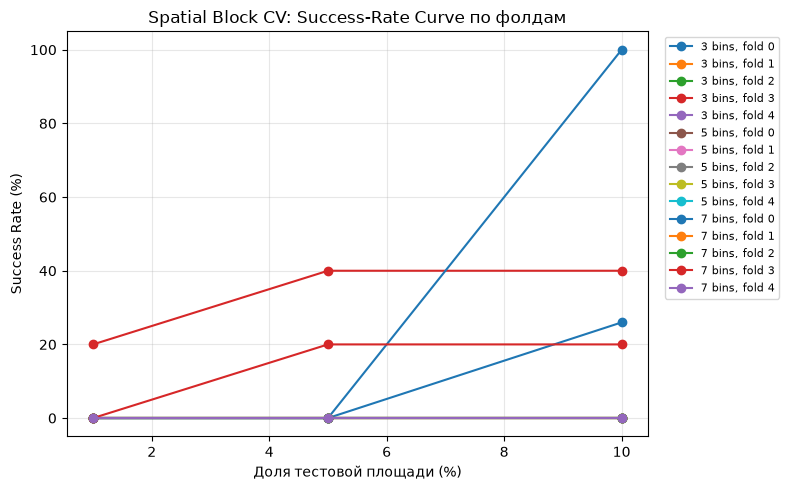

In [6]:

fig, ax = plt.subplots(figsize=(8, 5))
for (n_bins, fold), group in cv_results.groupby(["n_bins", FOLD]):
    group = group.sort_values("area_fraction")
    ax.plot(
        group["area_fraction"] * 100,
        group["success_rate_expected"] * 100,
        marker="o", label=f"{n_bins} bins, fold {fold}"
    )
ax.set_xlabel("Доля тестовой площади (%)")
ax.set_ylabel("Success Rate (%)")
ax.set_title("Spatial Block CV: Success-Rate Curve по фолдам")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


## 7. Ограничения и интерпретация

- `is_deposit=0` — Unlabeled, не Negative.
- WoE отражает отношение частот в известных Positive и фоне, а не вероятность минерализации.
- Суммирование одномерных WoE предполагает аддитивность; коррелирующие признаки могут давать double counting.
- При 11 Positive фолдовые оценки крайне нестабильны.
- Нельзя выбирать конфигурацию по одному лучшему фолду или exploratory score.
- Sampling bias пока не устранён; отсутствие дорог/плотности поисковых работ в таблице не позволяет полноценно проверить смещение изученности.

**Выводы заполняются после выполнения ноутбука в целевой среде. Не переносить старые метрики из предыдущей версии.**

## 8. Сохранение результатов

Сохраняются exploratory scores, фолдовые CV-метрики, OOF scores, ранги Positive и финальные таблицы WoE. Экспортируемая модель обучена на всей таблице и предназначена только для исследовательской карты.

In [7]:

OUTPUT_DIR = ROOT / "data" / "processed" / "woe_geological_baseline"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

exploratory_export = df[["x", "y", TARGET, FOLD]].copy()
exploratory_export["woe_score_exploratory"] = full_score
exploratory_export.to_csv(OUTPUT_DIR / "exploratory_scores.csv", index=False)
cv_results.to_csv(OUTPUT_DIR / "spatial_cv_metrics.csv", index=False)
oof_scores.to_csv(OUTPUT_DIR / "spatial_cv_oof_scores.csv", index=False)
deposit_ranks.to_csv(OUTPUT_DIR / "deposit_ranks_in_test_folds.csv", index=False)

model_export = {}
for feature, model in full_model.items():
    model_export[feature] = {
        "categorical": model["categorical"],
        "edges": model["edges"].tolist() if model["edges"] is not None else None,
        "table": {str(k): float(v) for k, v in model["table"].items()}
    }
with open(OUTPUT_DIR / "woe_model_exploratory.json", "w", encoding="utf-8") as f:
    json.dump(model_export, f, ensure_ascii=False, indent=2)

print("Saved to:", OUTPUT_DIR)


Saved to: d:\Uni\Сборники\3 курс\Командная разработка\Удалённый репозиторий\data\processed\woe_geological_baseline


In [8]:
# Единый экспорт результатов WoE geological (6 признаков)

from pathlib import Path

COMPARISON_DIR = ROOT / "data" / "processed" / "woe_comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

geological_export = cv_results.copy()

geological_export["model"] = "WoE geological"
geological_export["features"] = ", ".join(FEATURES)
geological_export["spatial_cv"] = True
geological_export["alpha"] = ALPHA

common_columns = [
    "model", "features", "spatial_cv",
    "n_bins", "alpha", "fold_id",
    "area_fraction", "top_k_cells",
    "precision_at_k_expected", "success_rate_expected",
    "found_expected", "test_deposits",
]

# Унифицируем названия метрик
geological_export = geological_export.rename(columns={
    "precision_at_k_expected": "precision_at_k",
    "success_rate_expected": "success_rate",
})

geological_export = geological_export[
    [c for c in common_columns if c in geological_export.columns]
]

geological_export.to_csv(
    COMPARISON_DIR / "geological_6features.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Экспортировано:", COMPARISON_DIR / "geological_6features.csv")
display(geological_export.head())

Экспортировано: d:\Uni\Сборники\3 курс\Командная разработка\Удалённый репозиторий\data\processed\woe_comparison\geological_6features.csv


,model,features,spatial_cv,n_bins,alpha,fold_id,area_fraction,top_k_cells,found_expected,test_deposits
0,WoE geological,"elevation, magnetic, gravity, dist_fault_km, d...",True,3,0.5,0,0.01,49,0.00000,1
1,WoE geological,"elevation, magnetic, gravity, dist_fault_km, d...",True,3,0.5,0,0.05,244,0.00000,1
2,WoE geological,"elevation, magnetic, gravity, dist_fault_km, d...",True,3,0.5,0,0.10,488,0.25974,1
3,WoE geological,"elevation, magnetic, gravity, dist_fault_km, d...",True,3,0.5,1,0.01,73,0.00000,2
4,WoE geological,"elevation, magnetic, gravity, dist_fault_km, d...",True,3,0.5,1,0.05,364,0.00000,2
